In [1]:
    from google.colab import drive
    drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
# Colab cell 1
%pip -q install ultralytics opencv-python
import os, json, pathlib, cv2, numpy as np
from ultralytics import YOLO
from google.colab.patches import cv2_imshow
from IPython.display import Image as ShowImage, display


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 19.0 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


In [19]:
# CHANGE these to your actual paths
WEIGHTS_PATH = "/content/drive/MyDrive/77_percent_F1_score_150e.pt"   # or "/content/best.pt"
IMAGE_PATH   = "/content/drive/MyDrive/YOLO_solo/raw_image/canangsari_crop2.jpeg"  # or "/content/test.jpg"

assert os.path.exists(WEIGHTS_PATH), f"Weights not found: {WEIGHTS_PATH}"
assert os.path.exists(IMAGE_PATH),   f"Image not found:   {IMAGE_PATH}"


In [20]:
model = YOLO(WEIGHTS_PATH)
print("Classes:", model.names)


Classes: {0: '0', 1: '1', 2: '2', 3: '3', 4: '4', 5: '5', 6: '6', 7: '7', 8: '8', 9: '9', 10: 'a-kara', 11: 'adeg-adeg', 12: 'ba', 13: 'ba-kembang', 14: 'bisah-h-', 15: 'ca', 16: 'cecek-ng-', 17: 'da', 18: 'da-madu', 19: 'e-kara', 20: 'end', 21: 'ga', 22: 'ga-gara', 23: 'gantungan-ba', 24: 'gantungan-ca', 25: 'gantungan-da', 26: 'gantungan-ga', 27: 'gantungan-ha', 28: 'gantungan-ja', 29: 'gantungan-ka', 30: 'gantungan-la', 31: 'gantungan-ma', 32: 'gantungan-na', 33: 'gantungan-nya', 34: 'gantungan-pa', 35: 'gantungan-ra', 36: 'gantungan-sa', 37: 'gantungan-ta', 38: 'gantungan-wa', 39: 'gantungan-ya', 40: 'ha', 41: 'i-kara', 42: 'ja', 43: 'ja-jera', 44: 'ka', 45: 'la', 46: 'le-lenga', 47: 'ma', 48: 'na', 49: 'na-rambat', 50: 'nga', 51: 'nya', 52: 'o-kara', 53: 'pa', 54: 'pa-kapal', 55: 'pepet', 56: 'ra', 57: 'ra-repa', 58: 'sa', 59: 'sa-saga', 60: 'sa-sapa', 61: 'suku', 62: 'surang-r-', 63: 'ta', 64: 'ta-latik', 65: 'ta-tawa', 66: 'taleng', 67: 'tedong', 68: 'u-kara', 69: 'ulu', 70: 'wa

In [21]:
def _color_for_class(cid: int):
    """Deterministic color per class id."""
    rng = np.random.default_rng(cid)
    return tuple(int(x) for x in rng.integers(64, 256, size=3))  # B,G,R

def recognize_image(
    image_path: str,
    conf: float = 0.25,
    iou: float = 0.5,
    img_size: int = 640,
    out_path: str | None = None,
    save_json: bool = True,
    show: bool = True,
    # <<— control label/box appearance here
    label_font_scale: float = 0.42,   # smaller text (try 0.30–0.50)
    label_thickness: int = 1,
    box_thickness: int = 2,
    include_conf: bool = True
):
    # run YOLO
    results = model.predict(source=image_path, conf=conf, iou=iou, imgsz=img_size, verbose=False)
    r = results[0]
    names = model.names

    # read original image for custom drawing
    im = cv2.imread(image_path)  # BGR
    if im is None:
        raise RuntimeError(f"Failed to read image: {image_path}")

    dets_json = []
    if r.boxes is not None and len(r.boxes):
        xyxy = r.boxes.xyxy.cpu().numpy().astype(int)
        cls  = r.boxes.cls.cpu().numpy().astype(int)
        confs= r.boxes.conf.cpu().numpy()

        for i, (x1, y1, x2, y2) in enumerate(xyxy):
            cid = int(cls[i])
            score = float(confs[i])
            label = names.get(cid, str(cid))
            if include_conf:
                label = f"{label} {score:.2f}"

            color = _color_for_class(cid)

            # draw box
            cv2.rectangle(im, (x1, y1), (x2, y2), color, thickness=box_thickness)

            # measure text + draw filled bg
            (tw, th), bl = cv2.getTextSize(label, cv2.FONT_HERSHEY_SIMPLEX, label_font_scale, label_thickness)
            # place above the box if there’s room, else inside
            y_text = y1 - 3
            if y_text - th - 2 < 0:
                y_text = y1 + th + 3
            # cv2.rectangle(im, (x1, y_text - th - 2), (x1 + tw + 2, y_text + 2), color, thickness=-1) # Commented out to remove background
            cv2.putText(im, label, (x1 + 1, y_text), cv2.FONT_HERSHEY_SIMPLEX, label_font_scale,
                        (255, 255, 255), label_thickness, lineType=cv2.LINE_AA)

            dets_json.append({
                "bbox_xyxy": [int(x1), int(y1), int(x2), int(y2)],
                "class_id": cid,
                "class_name": names.get(cid, str(cid)),
                "confidence": score
            })

    # save output image
    p = pathlib.Path(image_path)
    out_path = out_path or str(p.with_name(p.stem + "_det" + p.suffix))
    ok = cv2.imwrite(out_path, im)
    if not ok:
        raise RuntimeError(f"Failed to write annotated image to {out_path}")

    # optional sidecar JSON
    json_path = None
    if save_json:
        json_path = str(pathlib.Path(out_path).with_suffix(".json"))
        with open(json_path, "w") as f:
            json.dump({"image": image_path, "detections": dets_json}, f, indent=2)

    if show:
        cv2_imshow(im)

    return {"image_out": out_path, "json_out": json_path}

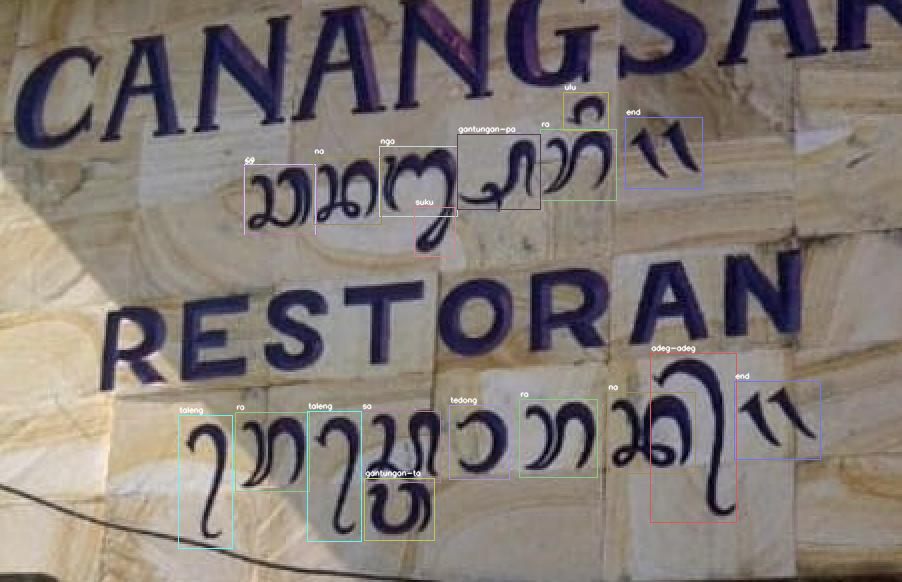

{'image_out': '/content/drive/MyDrive/YOLO_solo/raw_image/canangsari_crop2_det.jpeg',
 'json_out': '/content/drive/MyDrive/YOLO_solo/raw_image/canangsari_crop2_det.json'}

In [22]:
out = recognize_image(
    IMAGE_PATH,
    # tweak these to get even smaller labels if needed:
    label_font_scale=0.25,   # ↓ make smaller here
    label_thickness=1,
    box_thickness=1,
    include_conf=False
)
out